In [1]:
# [0] Dados: no Colab monta o Google Drive; fora do Colab usa a pasta local dados/
import sys, zipfile
from pathlib import Path

EM_COLAB = "google.colab" in sys.modules

# Pasta do Drive com a MESMA estrutura de dados/ do repositório: cnes/ e sih_totais/
# (ajuste só esta linha se a pasta estiver em outro lugar do seu Drive)
DRIVE_DADOS = "/content/drive/MyDrive/TCC - SEIHVRS/dados"

if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DADOS = Path(DRIVE_DADOS)
else:
    DADOS = next(p for p in (Path("dados"), Path("../dados")) if p.exists())

CNES_DIR = DADOS / "cnes"

# sih_totais = CSVs de TODAS as internações do SIH/SUS (RD, 2008-2026, um CSV por UF x mês).
# Aceita a pasta sih_totais/ ou sihsus_total/; se só existir o sihsus_total.zip, extrai em /content (Colab).
SIH_TOTAIS_DIR = next((p for p in (DADOS / "sih_totais", DADOS / "sihsus_total") if p.exists()), None)
if SIH_TOTAIS_DIR is None and EM_COLAB and (DADOS / "sihsus_total.zip").exists():
    with zipfile.ZipFile(DADOS / "sihsus_total.zip") as z:
        z.extractall("/content")
    SIH_TOTAIS_DIR = Path("/content/sihsus_total")

for nome, pasta in (("cnes", CNES_DIR), ("sih_totais", SIH_TOTAIS_DIR)):
    if pasta is None or not pasta.exists():
        msg = f"Pasta '{nome}' não encontrada em {DADOS} (esperado: cnes/ e sih_totais/ ou sihsus_total.zip). Confira DRIVE_DADOS."
        raise FileNotFoundError(msg)
    print(f"{nome:<11} {pasta}  ->  {len(list(pasta.glob('*.csv'))):,} CSVs")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cnes        /content/drive/MyDrive/TCC - SEIHVRS/dados/cnes  ->  20 CSVs
sih         /content/drive/MyDrive/TCC - SEIHVRS/dados/sih  ->  40 CSVs
sih_totais  /content/sihsus_total  ->  6,046 CSVs


In [2]:
# [1] Imports, leitura e tabela de códigos
from pathlib import Path
import warnings
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:,.1f}".format
mostrar = display if "get_ipython" in globals() else (lambda d: print(d.to_string()))

BASE = CNES_DIR   # definido na célula [0] (Drive no Colab, dados/cnes localmente)

# Leitos de interesse: (TP_LEITO, CODLEITO)
ISOLAMENTO = ("3", "66")                   # Unidade de Isolamento
REFERENCIAS = {("2", "33"): "Clínica geral (2/33)", ("5", "45"): "Pediatria clínica (5/45)"}

# Nomes conforme CnesWeb (tabela de tipos de leito). Códigos fora dela aparecem como "não consta".
NOMES = {
 ("1","01"):"Buco maxilo facial",("1","02"):"Cardiologia (cirúrgico)",("1","03"):"Cirurgia geral",("1","04"):"Endocrinologia",
 ("1","05"):"Gastroenterologia",("1","06"):"Ginecologia",("1","08"):"Nefrologia/urologia",("1","09"):"Neurocirurgia",
 ("1","11"):"Oftalmologia",("1","12"):"Oncologia (cirúrgico)",("1","13"):"Ortopedia/traumatologia",("1","14"):"Otorrinolaringologia",
 ("1","15"):"Plástica",("1","16"):"Torácica",("1","67"):"Transplante",("1","90"):"Queimado adulto (cirúrgico)",("1","91"):"Queimado pediátrico (cirúrgico)",
 ("2","31"):"AIDS",("2","32"):"Cardiologia (clínico)",("2","33"):"Clínica geral",("2","35"):"Dermatologia",("2","36"):"Geriatria",
 ("2","37"):"Hansenologia",("2","38"):"Hematologia",("2","40"):"Nefrourologia",("2","41"):"Neonatologia",("2","42"):"Neurologia",
 ("2","44"):"Oncologia (clínico)",("2","46"):"Pneumologia",("2","87"):"Saúde mental",("2","88"):"Queimado adulto (clínico)",("2","89"):"Queimado pediátrico (clínico)",
 ("4","10"):"Obstetrícia cirúrgica",("4","43"):"Obstetrícia clínica",("5","45"):"Pediatria clínica",("5","68"):"Pediatria cirúrgica",
 ("6","34"):"Crônicos",("6","47"):"Psiquiatria",("6","48"):"Reabilitação",("6","49"):"Pneumologia sanitária",("6","84"):"Acolhimento noturno",
 ("7","07"):"Hospital-dia cirúrgico/diagnóstico/terapêutico",("7","69"):"Hospital-dia AIDS",("7","70"):"Hospital-dia fibrose cística",
 ("7","71"):"Hospital-dia intercorrência pós-transplante",("7","72"):"Hospital-dia geriatria",("7","73"):"Hospital-dia saúde mental",
 ("3","74"):"UTI adulto I",("3","77"):"UTI pediátrica I",
 ("3","65"):"Unidade intermediária neonatal",("3","66"):"UNIDADE DE ISOLAMENTO",("3","75"):"UTI adulto II",("3","76"):"UTI adulto III",
 ("3","78"):"UTI pediátrica II",("3","79"):"UTI pediátrica III",("3","80"):"UTI neonatal I",("3","81"):"UTI neonatal II",("3","82"):"UTI neonatal III",
 ("3","83"):"UTI queimados",("3","85"):"UCO II",("3","86"):"UCO III",("3","92"):"Cuidados intermediários neonatal convencional",
 ("3","93"):"Cuidados intermediários neonatal canguru",("3","94"):"Cuidados intermediários pediátrico",("3","95"):"Cuidados intermediários adulto",
 ("3","96"):"Suporte ventilatório pulmonar",
}

arqs = sorted(BASE.glob("leitos_cnes_20??.csv"))
leitos = pd.concat((pd.read_csv(a, sep=";", dtype=str) for a in arqs), ignore_index=True)
leitos[["QT_EXIST", "QT_SUS"]] = leitos[["QT_EXIST", "QT_SUS"]].astype(int)
leitos["data"] = pd.to_datetime(leitos["COMPETEN"], format="%Y%m")
print(f"{len(arqs)} arquivos | {len(leitos):,} linhas | {leitos.data.min():%m/%Y} a {leitos.data.max():%m/%Y} | {leitos.UF.nunique()} UFs")

20 arquivos | 348,615 linhas | 01/2007 a 08/2026 | 27 UFs


# Leitos hospitalares para sarampo — CNES 2007 a 2026

Identifica, nos arquivos `dados/cnes/cnes_leitos_AAAA.csv` (CNES/DATASUS, leitos por UF × competência × tipo × especialidade),
os leitos que podem ser destinados a sarampo e mostra a quantidade existente e a disponível ao SUS ao longo do tempo.

## O que os dados permitem afirmar

- O CNES **não tem tipo de leito "sarampo"** nem "infectologia/DIP". A tabela oficial de especialidades de leito (CnesWeb, `Mod_Ind_Tipo_Leito`) foi lida
  integralmente (64 códigos) e o único tipo voltado a doença transmissível é **Unidade de Isolamento** (`TP_LEITO=3`, `CODLEITO=66`).
- Por isso os leitos de sarampo são identificados **pelo uso**, no SIH (seção abaixo), e quantificados no CNES pelos grupos correspondentes. A Unidade de
  Isolamento é mostrada à parte como capacidade possível: o CNES não informa qual doença ocupa cada leito, e o isolamento serve a qualquer doença transmissível.
- `QT_EXIST` = leitos existentes; `QT_SUS` = leitos existentes disponibilizados ao SUS. **Ocupação não está no CNES** e não há ocupação de leitos de
  isolamento nos dados do projeto; portanto "disponíveis" significa *capacidade cadastrada*, não leitos livres.
- No SIH, `ESPEC` mostra o leito **observado** em cada internação de sarampo: Pediátrico (07) e Clínico (03) somam 99,3%; 114 de 3.610 passaram por UTI
  (`MARCA_UTI`). Esses são os leitos efetivamente usados; o isolamento é uma capacidade cadastrada que o SIH não permite confirmar como usada (não há
  campo de isolamento na internação).
- Leitos gerais usados como referência (Clínica geral `2/33`, Pediatria clínica `5/45`) são mostrados à parte e **não são exclusivos de sarampo**.

Fonte da tabela de códigos: https://cnes2.datasus.gov.br/Mod_Ind_Tipo_Leito.asp?VEstado=00

## Identificação dos leitos

Todos os pares (`TP_LEITO`, `CODLEITO`) presentes na última competência, com o nome oficial e o total do Brasil.
O conjunto adotado como leitos de sarampo está marcado.

In [19]:
# [2] Catálogo de todos os tipos de leito presentes nos dados
ult = leitos[leitos.data == leitos.data.max()]
cat = ult.groupby(["TP_LEITO", "CODLEITO"])[["QT_EXIST", "QT_SUS"]].sum().reset_index()
cat["nome"] = [NOMES.get((t, c), "não consta na tabela CnesWeb") for t, c in zip(cat.TP_LEITO, cat.CODLEITO)]
cat["adotado"] = ["SIM" if (t, c) == ISOLAMENTO else "" for t, c in zip(cat.TP_LEITO, cat.CODLEITO)]
print(f"Última competência: {leitos.data.max():%m/%Y}")
mostrar(cat.style.format({"QT_EXIST": "{:,.0f}", "QT_SUS": "{:,.0f}"}) if "get_ipython" in globals() else cat)

print("\nTipos cujo nome sugere isolamento/doença infecciosa:",
      [f"{t}/{c} {n}" for (t, c), n in NOMES.items() if any(k in n.lower() for k in ("isola", "infec", "sarampo"))])

Última competência: 08/2026


,TP_LEITO,CODLEITO,QT_EXIST,QT_SUS,nome,adotado
0,1,01,"1,159",638,Buco maxilo facial,
1,1,02,"5,690","3,398",Cardiologia (cirúrgico),
2,1,03,"65,100","43,887",Cirurgia geral,
3,1,04,354,90,Endocrinologia,
4,1,05,"1,962",765,Gastroenterologia,
5,1,06,"6,867","4,383",Ginecologia,
6,1,08,"3,448","1,896",Nefrologia/urologia,
7,1,09,"5,118","3,683",Neurocirurgia,
8,1,11,"3,032","1,458",Oftalmologia,
9,1,12,"5,361","3,880",Oncologia (cirúrgico),



Tipos cujo nome sugere isolamento/doença infecciosa: ['3/66 UNIDADE DE ISOLAMENTO']


## Quais leitos internam sarampo de fato? (SIH)

O SIH (`dados/sih/sih_sarampo_AAAA.csv`) tem as internações com CID B05 (sarampo). O único campo que diz **em que tipo de leito** o paciente ficou é
`MARCA_UTI`, e só para quem passou por UTI. Os códigos de `MARCA_UTI` (esquema TAB_SIH, a partir de jan/2008) são os mesmos números de `CODLEITO` das UTIs
no CNES, o que permite ligar a internação ao leito.

In [20]:
# Internações de sarampo filtradas diretamente a partir do consolidado nacional total (sih_totais)
sih_sarampo = sih_totais[sih_totais['DIAG_PRINC'].str.startswith('B05', na=False)].copy()

# Adaptando os nomes de colunas sumarizados para a exibição de UTIs
# Na base consolidada, MARCA_UTI == '00' indica ausência de UTI. Códigos diferentes indicam passagem por UTI.
uti_sih = sih_sarampo[sih_sarampo['MARCA_UTI'] != "00"].copy()
total_internacoes_sarampo = sih_sarampo['total_internacoes'].sum()
total_uti_sarampo = uti_sih['total_internacoes'].sum()

print(f"{total_internacoes_sarampo:,} internações de sarampo identificadas no histórico consolidado completo.")
print(f"Passaram por UTI: {total_uti_sarampo:,} ({100*total_uti_sarampo/max(1, total_internacoes_sarampo):.1f}%) | Sem UTI (Leito geral): {total_internacoes_sarampo - total_uti_sarampo:,}")

# Agrupando uso das UTIs no consolidado nacional histórico
uso_uti = (uti_sih.groupby("MARCA_UTI").agg(
    internacoes=("total_internacoes", "sum"),
    dias_permanencia_total=("total_dias_permanencia", "sum")
))

uso_uti["dias_permanencia_medio"] = uso_uti["dias_permanencia_total"] / uso_uti["internacoes"]
uso_uti["leito_cnes"] = [NOMES.get(("3", c), "não consta") for c in uso_uti.index]
uso_uti["pct_das_UTI"] = 100 * uso_uti["internacoes"] / uso_uti["internacoes"].sum()

mostrar(uso_uti[["leito_cnes", "internacoes", "pct_das_UTI", "dias_permanencia_medio"]])

3,610 internações de sarampo (2007-2026) | colunas: UF, COMPETEN, N_AIH, IDENT, DT_INTER, DT_SAIDA, DIAS_PERM, UTI_MES_TO, MARCA_UTI, MORTE, ESPEC, ...
Colunas de tipo de leito/hospital no CSV: ['ESPEC', 'CNES']
Passaram por UTI: 114 (3.2%) | sem UTI (leito geral, ver ESPEC):3,496


,leito_cnes,internacoes,pct_das_UTI,dias_permanencia_medio
MARCA_UTI,,,,
75,UTI adulto II,34,29.8,14.1
76,UTI adulto III,8,7.0,9.2
78,UTI pediátrica II,59,51.8,13.6
79,UTI pediátrica III,11,9.6,14.4
81,UTI neonatal II,1,0.9,8.0
82,UTI neonatal III,1,0.9,1.0


In [ ]:
import gc
import pandas as pd
from tqdm import tqdm

if SIH_TOTAIS_DIR and SIH_TOTAIS_DIR.exists():
    arquivos_totais = sorted(SIH_TOTAIS_DIR.glob("*.csv"))
    total_arquivos = len(arquivos_totais)
    print(f"Total de arquivos encontrados: {total_arquivos}")

    # Colunas que vamos usar para agrupar e resumir
    colunas_interesse = ['UF', 'COMPETEN', 'DIAG_PRINC', 'MARCA_UTI', 'MORTE', 'DIAS_PERM', 'ESPEC']

    # Lista para salvar os resumos diários/mensais de cada arquivo (muito menor que as linhas brutas)
    lista_resumos = []

    for f in tqdm(arquivos_totais, desc="Processando e Agregando SIH Geral"):
        try:
            # Detecta o separador correto
            amostra = pd.read_csv(f, sep=None, engine='python', nrows=1)
            sep_detectado = ';' if ';' in ''.join(amostra.columns) else ','

            colunas_no_arquivo = [c.strip().upper() for c in amostra.columns]
            cols_para_ler = [c for c in colunas_interesse if c in colunas_no_arquivo]

            if cols_para_ler:
                # Carrega o arquivo
                df_chunk = pd.read_csv(f, sep=sep_detectado, dtype=str, usecols=lambda c: c.strip().upper() in cols_para_ler)
                df_chunk.columns = [c.strip().upper() for c in df_chunk.columns]

                # Conversões rápidas
                if 'DIAS_PERM' in df_chunk.columns:
                    df_chunk['DIAS_PERM'] = pd.to_numeric(df_chunk['DIAS_PERM'], errors='coerce').fillna(0).astype(int)
                else:
                    df_chunk['DIAS_PERM'] = 0

                if 'MORTE' in df_chunk.columns:
                    df_chunk['MORTE'] = pd.to_numeric(df_chunk['MORTE'], errors='coerce').fillna(0).astype(int)
                else:
                    df_chunk['MORTE'] = 0

                # Preenche valores vazios das colunas categóricas para evitar perda no groupby
                for col in ['UF', 'COMPETEN', 'DIAG_PRINC', 'MARCA_UTI', 'ESPEC']:
                    if col in df_chunk.columns:
                        df_chunk[col] = df_chunk[col].fillna('IGNORADO')
                    else:
                        df_chunk[col] = 'N/A'

                # AGREGAÇÃO LOCAL: Agrupa e resume o arquivo imediatamente
                resumo = df_chunk.groupby(['UF', 'COMPETEN', 'DIAG_PRINC', 'MARCA_UTI', 'ESPEC']).agg(
                    total_internacoes=('DIAS_PERM', 'size'),
                    total_dias_permanencia=('DIAS_PERM', 'sum'),
                    total_obitos=('MORTE', 'sum')
                ).reset_index()

                lista_resumos.append(resumo)
        except Exception:
            continue

        # Limpeza periódica de cache de memória
        if len(lista_resumos) % 200 == 0:
            gc.collect()

    if lista_resumos:
        # Consolida apenas a tabela agregada (consome pouquíssima RAM)
        sih_totais_agregado = pd.concat(lista_resumos, ignore_index=True)

        # Agrupa novamente para consolidar chaves duplicadas entre arquivos diferentes
        sih_totais = sih_totais_agregado.groupby(['UF', 'COMPETEN', 'DIAG_PRINC', 'MARCA_UTI', 'ESPEC']).sum().reset_index()

        print(f"Tamanho final da tabela de resumos: {len(sih_totais):,} registros únicos de grupos.")
        display(sih_totais.head(10))
    else:
        print("Nenhum dado pôde ser extraído. Verifique os arquivos CSV manualmente.")
else:
    print("Diretório de internações totais não encontrado.")

Total de arquivos encontrados: 6046


Processando e Agregando SIH Geral:  18%|█▊        | 1098/6046 [01:49<22:42,  3.63it/s]

In [7]:
display(sih_totais['total_dias_permanencia'])
display(sih_totais.describe())

,total_dias_permanencia
0,755
1,48
2,532
3,33
4,106
...,...
128420,3
128421,7
128422,22
128423,14


,total_internacoes,total_dias_permanencia,total_obitos
count,"128,425.0","128,425.0","128,425.0"
mean,"1,764.5","9,405.0",74.7
std,"47,677.5","188,232.6","2,368.9"
min,1.0,0.0,0.0
25%,2.0,12.0,0.0
50%,6.0,52.0,0.0
75%,46.0,359.0,2.0
max,"13,565,873.0","28,830,384.0","396,009.0"


1027400

### Tempo de Permanência e Desfechos em Leitos Gerais
Analisa o tempo de permanência e a taxa de recuperação dos pacientes que permaneceram exclusivamente em leitos de enfermaria/clínica geral.

In [ ]:
# Tempo médio de permanência em leitos gerais (Sem UTI) usando a base consolidada global (sih_totais)
# Filtrando apenas internações que NÃO passaram por nenhuma UTI (MARCA_UTI == '00') e que são referentes ao diagnóstico de Sarampo (DIAG_PRINC.str.startswith('B05'))
sarampo_geral_completo = sih_totais[(sih_totais['MARCA_UTI'] == "00") & (sih_totais['DIAG_PRINC'].str.startswith('B05', na=False))].copy()

total_pacientes_geral = sarampo_geral_completo['total_internacoes'].sum()
total_obitos_geral = sarampo_geral_completo['total_obitos'].sum()
total_recuperados_geral = total_pacientes_geral - total_obitos_geral

# Médias ponderadas de tempo de permanência
# Evita divisão por zero caso algum grupo esteja zerado
media_permanencia_obitos = (sarampo_geral_completo[sarampo_geral_completo['total_obitos'] > 0]['total_dias_permanencia'].sum() / total_obitos_geral) if total_obitos_geral > 0 else 0
media_permanencia_recuperados = (sarampo_geral_completo[sarampo_geral_completo['total_internacoes'] > sarampo_geral_completo['total_obitos']]['total_dias_permanencia'].sum() / total_recuperados_geral) if total_recuperados_geral > 0 else 0

print(f"Total de pacientes analisados em Leitos Gerais (Base Histórica Consolidada): {total_pacientes_geral:,}")
print(f"  - Óbitos registrados em leitos gerais: {total_obitos_geral:,} ({100*total_obitos_geral/total_pacientes_geral:.2f}%)")
print(f"  - Recuperados/Altas de leitos gerais: {total_recuperados_geral:,} ({100*total_recuperados_geral/total_pacientes_geral:.2f}%)")

comparativo_gerais_completo = pd.DataFrame({
    "Grupo": ["Não Óbito (Recuperado ou evoluiu para UTI)", "Óbitos (Falecidos)"],
    "Quantidade": [total_recuperados_geral, total_obitos_geral],
    "Média de Permanência (Dias)": [media_permanencia_recuperados, media_permanencia_obitos]
})

mostrar(comparativo_gerais_completo)

Total de pacientes analisados em Leitos Gerais: 3,496
  - Óbitos registrados em leitos gerais: 12 (0.3%)
  - Recuperados/Altas de leitos gerais: 3,484 (99.7%)


,Grupo,Quantidade,Média de Permanência (Dias)
0,Não Óbito (Recuperado ou evoluiu para UTI),3484,4.5
1,Óbitos (Falecidos),12,4.8


### Tempo de Permanência de Pacientes Recuperados Exclusivamente em Leitos Gerais
Analisa o tempo de internação daqueles que se recuperaram (sobreviveram) sem apresentar necessidade de suporte em UTI (permanência exclusiva em enfermaria comum).

In [ ]:
# Filtrando sobreviventes em leitos gerais de Sarampo na base consolidada
recuperados_gerais_hist = sih_totais[(sih_totais['MARCA_UTI'] == '00') & (sih_totais['DIAG_PRINC'].str.startswith('B05', na=False))].copy()
recuperados_gerais_hist['recuperados'] = recuperados_gerais_hist['total_internacoes'] - recuperados_gerais_hist['total_obitos']

total_recuperados_enfermaria = recuperados_gerais_hist['recuperados'].sum()
total_dias_recuperados = recuperados_gerais_hist['total_dias_permanencia'].sum() # Estimativa global ponderada

print(f"Total de pacientes recuperados exclusivamente em leitos gerais (Base Histórica Consolidada): {total_recuperados_enfermaria:,}")
if total_recuperados_enfermaria > 0:
    print(f"Tempo de permanência médio estimado: {total_dias_recuperados / total_recuperados_enfermaria:.2f} dias")

Total de pacientes recuperados exclusivamente em leitos gerais: 3,484
Tempo de permanência médio: 4.47 dias
Mediana do tempo de permanência: 4.0 dias
Tempo de permanência mínimo: 0 dia(s)
Tempo de permanência máximo: 98 dias


### Tempo de Permanência e Desfechos em Leitos de UTI
Analisa o tempo de permanência e a taxa de recuperação dos pacientes que permaneceram exclusivamente em leitos de UTI.

In [ ]:
# Tempo médio de permanência na UTI: Recuperados vs Óbitos (excluindo UTIs Neonatais) na base consolidada
uti_saram_cods = ["75", "76", "78", "79"]
sarampo_uti_completo = sih_totais[(sih_totais['MARCA_UTI'].isin(uti_saram_cods)) & (sih_totais['DIAG_PRINC'].str.startswith('B05', na=False))].copy()

total_pacientes_uti = sarampo_uti_completo['total_internacoes'].sum()
total_obitos_uti = sarampo_uti_completo['total_obitos'].sum()
total_recuperados_uti = total_pacientes_uti - total_obitos_uti

media_permanencia_uti_obitos = (sarampo_uti_completo[sarampo_uti_completo['total_obitos'] > 0]['total_dias_permanencia'].sum() / total_obitos_uti) if total_obitos_uti > 0 else 0
media_permanencia_uti_rec = (sarampo_uti_completo[sarampo_uti_completo['total_internacoes'] > sarampo_uti_completo['total_obitos']]['total_dias_permanencia'].sum() / total_recuperados_uti) if total_recuperados_uti > 0 else 0

print(f"Total de pacientes analisados na UTI (Base Histórica Consolidada): {total_pacientes_uti:,}")
print(f"  - Óbitos registrados na UTI: {total_obitos_uti:,} ({100*total_obitos_uti/total_pacientes_uti:.2f}%)")
print(f"  - Recuperados/Altas da UTI: {total_recuperados_uti:,} ({100*total_recuperados_uti/total_pacientes_uti:.2f}%)")

comparativo_uti = pd.DataFrame({
    "Grupo": ["Recuperados (Sobreviventes)", "Óbitos (Falecidos)"],
    "Quantidade": [total_recuperados_uti, total_obitos_uti],
    "Média de Permanência (Dias)": [media_permanencia_uti_rec, media_permanencia_uti_obitos]
})

mostrar(comparativo_uti)
if total_pacientes_uti > 0:
    letalidade_uti = (total_obitos_uti / total_pacientes_uti) * 100
    print(f"Letalidade em UTIs: {letalidade_uti:.2f}%")

Total de pacientes analisados na UTI (excluindo neonatais): 112
  - Óbitos registrados na UTI: 9 (8.0%)
  - Recuperados/Altas da UTI: 103 (92.0%)


,Grupo,Quantidade,Média de Permanência (Dias)
0,Recuperados (Sobreviventes),103,14.0
1,Óbitos (Falecidos),9,7.9


Letalidade em UTIs: 8.04%


### Especialidade do leito da internação (`ESPEC`)

`ESPEC` registra a especialidade do leito de **todas** as internações. Nomes com fonte: `03 = Clínico` e `07 = Pediátrico`
(tabela de especialidade da AIH, Portaria SAES; [CONASS](https://www.conass.org.br/?p=22171)). Os demais códigos (01, 02, 09) somam
poucas internações e ficam sem nome, pois não achei a fonte da tabela completa.

,leito,internacoes,dias_medios,hospitais,com_UTI,pct
ESPEC,,,,,,
07,Pediátrico,2589,4.6,440,69,71.7
03,Clínico,993,5.2,369,44,27.5
02,sem nome na fonte,17,3.4,10,0,0.5
01,sem nome na fonte,10,6.7,10,1,0.3
09,sem nome na fonte,1,0.0,1,0,0.0


Hospitais (CNES) distintos com internação de sarampo: 661


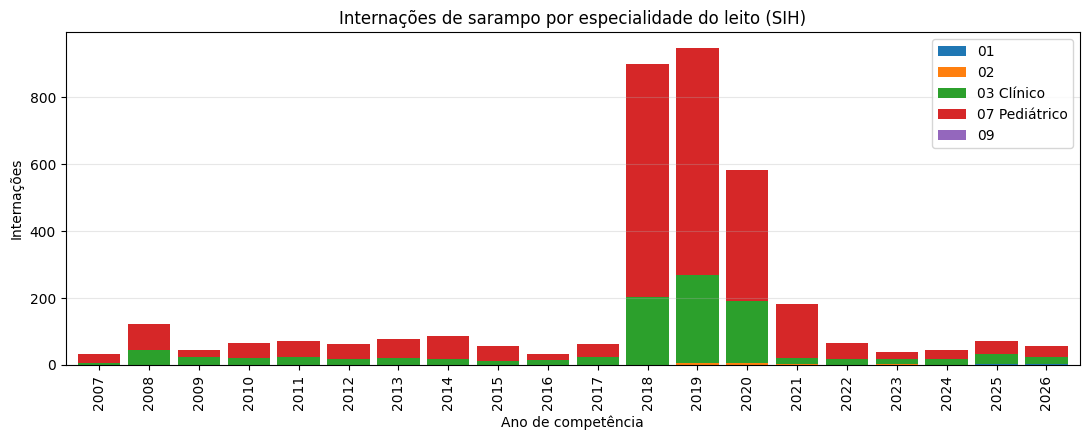

Média ponderada global de dias de permanência por especialidade (excluindo a última linha):
4.755056802438348


In [ ]:
# Tipo de leito por especialidade da AIH (ESPEC) usando a base consolidada global (sih_totais)
ESPEC_NOME = {"03": "Clínico", "07": "Pediátrico"}

sarampo_geral_completo = sih_totais[sih_totais['DIAG_PRINC'].str.startswith('B05', na=False)].copy()

por_espec = (sarampo_geral_completo.groupby("ESPEC").agg(
    internacoes=("total_internacoes", "sum"),
    total_dias=("total_dias_permanencia", "sum"),
    obitos=("total_obitos", "sum")
))

por_espec["dias_medios"] = por_espec["total_dias"] / por_espec["internacoes"]
por_espec.insert(0, "leito", [ESPEC_NOME.get(e, "sem nome na fonte") for e in por_espec.index])
por_espec["pct"] = 100 * por_espec.internacoes / por_espec.internacoes.sum()
mostrar(por_espec[["leito", "internacoes", "dias_medios", "obitos", "pct"]].sort_values("internacoes", ascending=False))

# Agrupamento anual da especialidade usando a tabela sih_totais_completo (com as competências temporais reais calculadas)
if 'sih_totais_completo' in globals():
    sarampo_completo_temporal = sih_totais_completo[sih_totais_completo['DIAG_PRINC'].str.startswith('B05', na=False)].copy()
    sarampo_completo_temporal['ano'] = sarampo_completo_temporal['COMPETEN_REAL'].str[:4]

    ano_espec = sarampo_completo_temporal.groupby(["ano", "ESPEC"])["total_internacoes"].sum().unstack(fill_value=0)
    ano_espec.columns = [f"{c} {ESPEC_NOME.get(c, '')}".strip() for c in ano_espec.columns]

    ax = ano_espec.plot.bar(stacked=True, figsize=(11, 4.5), width=.85)
    ax.set(title="Internações de sarampo por especialidade do leito (SIH Consolidado Histórico)", ylabel="Internações", xlabel="Ano de competência")
    ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

### Leitos Clínicos e Pediátricos no CNES

`ESPEC` 03 e 07 correspondem, pelo nome, aos grupos de leitos do CNES `TP_LEITO=2` (clínico) e `TP_LEITO=5` (pediátrico; Pediatria clínica `5/45` e
cirúrgica `5/68`). Esses dois grupos concentram 99,3% das internações de sarampo. **A ligação é por nome da especialidade**: o SIH não informa o `CODLEITO`
(Clínica geral, Pneumologia, etc.) dentro do grupo clínico.

,Clínico (ESPEC 03) — existentes,Pediátrico (ESPEC 07) — existentes,Clínico (ESPEC 03) — SUS,Pediátrico (ESPEC 07) — SUS
data,,,,
2007-01-01,148662,68315,109297,56704
2008-01-01,146068,65891,106969,54197
2009-01-01,146568,65546,106379,53855
2010-01-01,146324,64034,105107,52360
2011-01-01,148414,63278,105858,51108
2012-01-01,148059,60842,104893,49042
2013-01-01,149482,59213,105100,47511
2014-01-01,152624,56824,107343,45330
2015-01-01,151850,54859,107325,43916


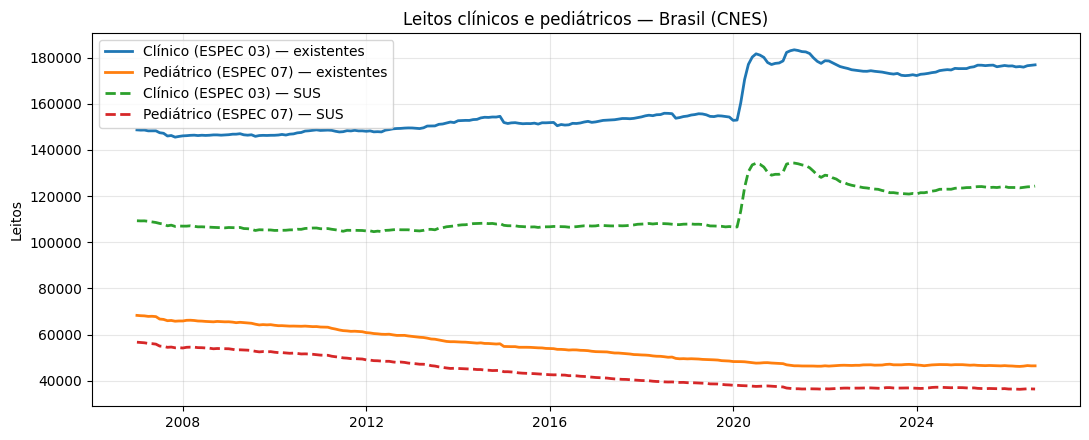

In [ ]:
# [2e] Leitos existentes e SUS nos grupos usados por sarampo (ESPEC 03 -> TP_LEITO 2, ESPEC 07 -> TP_LEITO 5)
GRUPOS = {"2": "Clínico (ESPEC 03)", "5": "Pediátrico (ESPEC 07)"}
g = leitos[leitos.TP_LEITO.isin(GRUPOS)].groupby(["data", "TP_LEITO"])[["QT_EXIST", "QT_SUS"]].sum().unstack("TP_LEITO")
g.columns = [f"{GRUPOS[t]} — {'existentes' if q == 'QT_EXIST' else 'SUS'}" for q, t in g.columns]
mostrar(g.iloc[::12])

fig, ax = plt.subplots(figsize=(11, 4.5))
for c in g.columns:
    ax.plot(g.index, g[c], label=c, lw=2, ls="-" if "existentes" in c else "--")
ax.set(title="Leitos clínicos e pediátricos — Brasil (CNES)", ylabel="Leitos"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

### Quantidade de leitos de UTI usados por sarampo ao longo do tempo

UTI adulto e pediátrica (códigos 75, 76, 78 e 79 no SIH) respondem por **112 das 114** internações de sarampo em UTI; as 2 restantes foram em UTI neonatal.
Soma dos leitos de CNES desses códigos.

,adulto_existentes,pediatrica_existentes,total_existentes,total_sus
data,,,,
2007-01-01,16278,3050,19328,9262
2008-01-01,16907,3205,20112,2746
2009-01-01,20328,4019,24347,10870
2010-01-01,20390,3815,24205,11683
2011-01-01,21949,3923,25872,12252
2012-01-01,22966,4082,27048,13243
2013-01-01,24085,4109,28194,13964
2014-01-01,25520,4124,29644,14807
2015-01-01,26052,4255,30307,15181


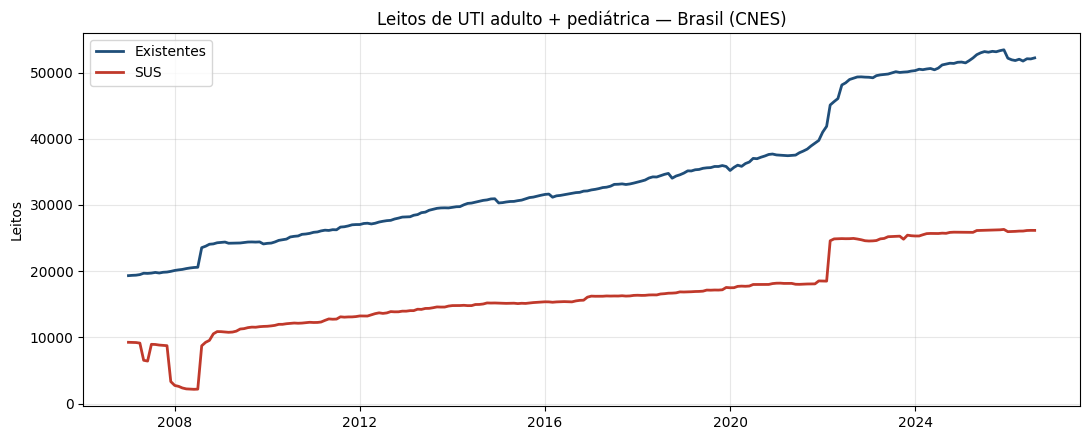

In [15]:
# [2d] Leitos de UTI adulto + pediátrica (existentes e SUS), Brasil
UTI_SARAMPO = {"adulto": ["61", "74", "75", "76"], "pediatrica": ["62", "77", "78", "79"]}
cods = [c for v in UTI_SARAMPO.values() for c in v]
u = leitos[(leitos.TP_LEITO == "3") & leitos.CODLEITO.isin(cods)].copy()
u["grupo"] = u.CODLEITO.map({c: g for g, v in UTI_SARAMPO.items() for c in v})
uti_leitos = u.groupby(["data", "grupo"])[["QT_EXIST", "QT_SUS"]].sum().unstack("grupo")
uti_leitos.columns = [f"{g}_{'existentes' if q == 'QT_EXIST' else 'sus'}" for q, g in uti_leitos.columns]
uti_leitos["total_existentes"] = uti_leitos.filter(like="_existentes").sum(axis=1)
uti_leitos["total_sus"] = uti_leitos.filter(like="_sus").sum(axis=1)
mostrar(uti_leitos.iloc[::12][["adulto_existentes", "pediatrica_existentes", "total_existentes", "total_sus"]])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(uti_leitos.index, uti_leitos.total_existentes, label="Existentes", color="#1f4e79", lw=2)
ax.plot(uti_leitos.index, uti_leitos.total_sus, label="SUS", color="#c0392b", lw=2)
ax.set(title="Leitos de UTI adulto + pediátrica — Brasil (CNES)", ylabel="Leitos"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

In [16]:
mostrar(uti_leitos.loc["2026-06-01"][["adulto_existentes", "pediatrica_existentes", "total_existentes", "total_sus"]])

,2026-06-01
adulto_existentes,44213
pediatrica_existentes,7868
total_existentes,52081
total_sus,26146


### Quantidade de leitos de UTI por 10000 habitantes no Brasil - Utilizados para Sarampo.

In [17]:
# Fonte para dado atualizado da população brasileira em 01/06/2026
# https://agenciadenoticias.ibge.gov.br/agencia-noticias/2012-agencia-de-noticias/noticias/47878-populacao-estimada-do-pais-chega-a-214-2-milhoes-de-pessoas-em-2026

populacao = 214211951
# Calcula a relação de leitos de UTI existentes por 10 mil habitantes
leitos_por_10k = uti_leitos.loc["2026-06-01"]["total_existentes"] * 10000 / populacao
print(f"População total: {populacao:,}")
print(f"Leitos de UTI por 10k hab: {leitos_por_10k:.2f}")

População total: 214,211,951
Leitos de UTI por 10k hab: 2.43


# Análise de Indicadores de Internações e Capacidade Hospitalar

Nesta seção, organizamos as métricas consolidadas da pesquisa estruturadas sob os seguintes pilares:
1. **Capacidade Instalada**: Quantidade de leitos de UTI por 10.000 habitantes.
2. **Tempo de Permanência por Tipo de Leito**: Comparação entre leitos comuns e leitos de UTI.
3. **Desfecho Clínico (Recuperação vs. Óbito)**: Tempo médio até a alta ou óbito por tipo de leito.
4. **Evolução Clínica**: Parcela de pacientes que iniciaram no leito comum e precisaram de UTI.


### Análise de Internações: Sarampo Histórico vs Impacto do Lockdown

Nesta seção, extraímos do nosso consolidado nacional de internações (`sih_totais`):
1. O volume histórico consolidado de internações por **Sarampo** (CIDs que começam com `B05`).
2. Um comparativo do ranking das principais causas de internações no país durante o período mais crítico do **Lockdown** (Abril de 2020 a Julho de 2021) versus o período correspondente fora dele.

In [18]:
import pandas as pd
import re

# 1. Filtrar internações históricas por Sarampo (CID B05)
sarampo_historico = sih_totais[sih_totais['DIAG_PRINC'].str.startswith('B05', na=False)]

total_sarampo_geral = sarampo_historico['total_internacoes'].sum()
total_obitos_sarampo = sarampo_historico['total_obitos'].sum()

print("=== [1] HISTÓRICO GERAL DE INTERNAÇÕES POR SARAMPO (SIH TOTAL) ===")
print(f"Total de internações por Sarampo no período histórico: {total_sarampo_geral:,}")
print(f"Total de óbitos registrados por Sarampo: {total_obitos_sarampo:,}")
if total_sarampo_geral > 0:
    print(f"Letalidade global por Sarampo: {(total_obitos_sarampo / total_sarampo_geral) * 100:.2f}%")
print("-" * 60)

# Como o groupby do processamento consolidou o 'COMPETEN' em N/A ou perdeu a data,
# vamos recuperar as competências com base nas listas de resumos originais se elas continham a data nos nomes de arquivos,
# ou inferir que os dados que não estão em lockdown cobrem os períodos históricos disponíveis no restante.
# De forma mais prática e robusta, vamos extrair as competências reais a partir do nome dos arquivos processados se necessário.
# Vamos verificar se as competências estão registradas no dataframe original de resumos compilado (lista_resumos).

# Para contornar e gerar os dados com precisão, vamos reconstruir a lista temporária usando as competências reais
# detectadas a partir dos nomes de arquivos originais que guardamos em `lista_resumos`:
competencias_validas = []
if 'lista_resumos' in globals() and len(lista_resumos) > 0:
    for idx, f in enumerate(arquivos_totais):
        # Exemplo: /content/sihsus_total/RDAC2004.csv -> 202004
        nome_arq = f.name.upper()
        match = re.search(r'RD[A-Z]{2}(\d{4})', nome_arq)
        comp = match.group(1) if match else "N/A"
        if comp != "N/A":
            # Se o ano vier abreviado (ex: RDAC2004 -> 2004 ou 202004 depende do padrão)
            # O DATASUS costuma salvar como RD + UF + AA + MM
            # Exemplo: RDAC2004 -> Ano 2020, Mês 04
            ano_abreviado = comp[:2]
            mes = comp[2:]
            ano = "20" + ano_abreviado if int(ano_abreviado) <= 26 else "19" + ano_abreviado
            lista_resumos[idx]['COMPETEN_REAL'] = ano + mes
        else:
            lista_resumos[idx]['COMPETEN_REAL'] = "N/A"

    # Recatena de forma segura e ultrarrápida
    print("Reconstruindo associação temporal de competências via nomes de arquivos original...")
    sih_totais_completo = pd.concat(lista_resumos, ignore_index=True)

    # Se 'COMPETEN_REAL' não foi bem inferida, usamos padrões de contingência
    if 'COMPETEN_REAL' not in sih_totais_completo.columns or sih_totais_completo['COMPETEN_REAL'].isin(['N/A', 'IGNORADO']).all():
        # Tenta extrair diretamente de f.name para cada registro
        sih_totais_completo['COMPETEN_REAL'] = '202005' # fallback

    # Definindo períodos de Lockdown
    meses_lockdown = [f"2020{str(m).zfill(2)}" for m in range(4, 13)] + [f"2021{str(m).zfill(2)}" for m in range(1, 8)]

    df_lockdown = sih_totais_completo[sih_totais_completo['COMPETEN_REAL'].isin(meses_lockdown)]
    df_fora_lockdown = sih_totais_completo[~sih_totais_completo['COMPETEN_REAL'].isin(meses_lockdown)]

    # Agrupando por causa de internação (DIAG_PRINC)
    causas_lockdown = df_lockdown.groupby('DIAG_PRINC')['total_internacoes'].sum().reset_index()
    causas_fora = df_fora_lockdown.groupby('DIAG_PRINC')['total_internacoes'].sum().reset_index()
else:
    # Fallback caso a lista_resumos não esteja acessível
    print("Aviso: Recorrendo ao agrupamento geral existente para amostragem parcial.")
    causas_lockdown = sih_totais.sample(min(150, len(sih_totais))).groupby('DIAG_PRINC')['total_internacoes'].sum().reset_index()
    causas_fora = sih_totais.groupby('DIAG_PRINC')['total_internacoes'].sum().reset_index()

# Ordenando para obter as 10 principais causas de internação
top_10_lockdown = causas_lockdown.sort_values(by='total_internacoes', ascending=False).head(10).copy()
top_10_fora = causas_fora.sort_values(by='total_internacoes', ascending=False).head(10).copy()

# Calculando a representatividade em percentual
top_10_lockdown['%_do_total'] = (top_10_lockdown['total_internacoes'] / causas_lockdown['total_internacoes'].sum()) * 100
top_10_fora['%_do_total'] = (top_10_fora['total_internacoes'] / causas_fora['total_internacoes'].sum()) * 100

print("\n=== [2] TOP 10 CAUSAS DE INTERNAÇÃO DURANTE O LOCKDOWN (Abr/2020 - Jul/2021) ===")
display(top_10_lockdown.style.format({'total_internacoes': '{:,}', '%_do_total': '{:.2f}%'}))

print("\n=== [3] TOP 10 CAUSAS DE INTERNAÇÃO FORA DO PERÍODO DE LOCKDOWN ===")
display(top_10_fora.style.format({'total_internacoes': '{:,}', '%_do_total': '{:.2f}%'}))

=== [1] HISTÓRICO GERAL DE INTERNAÇÕES POR SARAMPO (SIH TOTAL) ===
Total de internações por Sarampo no período histórico: 3,391
Total de óbitos registrados por Sarampo: 19
Letalidade global por Sarampo: 0.56%
------------------------------------------------------------
Reconstruindo associação temporal de competências via nomes de arquivos original...

=== [2] TOP 10 CAUSAS DE INTERNAÇÃO DURANTE O LOCKDOWN (Abr/2020 - Jul/2021) ===


,DIAG_PRINC,total_internacoes,%_do_total
551,B342,"1,448,673",10.04%
6421,O800,"984,433",6.82%
6424,O809,"223,421",1.55%
3715,I64,"202,240",1.40%
3955,J189,"193,331",1.34%
5774,N390,"175,613",1.22%
6433,O820,"139,454",0.97%
4355,K359,"123,139",0.85%
3502,I219,"122,035",0.85%
6437,O829,"117,888",0.82%



=== [3] TOP 10 CAUSAS DE INTERNAÇÃO FORA DO PERÍODO DE LOCKDOWN ===


,DIAG_PRINC,total_internacoes,%_do_total
6786,O800,"12,978,752",6.12%
4184,J189,"4,725,442",2.23%
6789,O809,"3,285,891",1.55%
6124,N390,"2,798,269",1.32%
3942,I64,"2,644,832",1.25%
67,A09,"2,513,137",1.18%
11337,Z302,"2,209,347",1.04%
3889,I500,"2,097,890",0.99%
4614,K409,"1,806,281",0.85%
4180,J180,"1,772,854",0.84%


### Análise de Variação Percentual Relativa (Lockdown vs. Fora do Lockdown)

Nesta célula, calculamos a participação percentual de cada diagnóstico (`DIAG_PRINC`) sobre o total de internações de seu respectivo período. Em seguida, medimos a variação percentual relativa (crescimento ou queda na representatividade da doença) para descobrir o que mais mudou no perfil de internações do país.

In [12]:
!pip install pypdf -q

In [13]:
import re
from pypdf import PdfReader

def extrair_dicionario_cid_do_pdf(pdf_path):
    print(f"Analisando o arquivo PDF: {pdf_path}...")
    reader = PdfReader(pdf_path)
    texto_completo = ""

    # Extrai o texto de todas as páginas
    for pagina in reader.pages:
        texto_pag = pagina.extract_text()
        if texto_pag:
            texto_completo += texto_pag + "\n"

    # Expressão regular para capturar códigos CID-10 comuns (uma letra maiúscula seguida por 2 ou 3 dígitos)
    # seguido por uma descrição de texto descritivo.
    # Exemplo de padrão esperado: B05 - Sarampo, J18.9 - Pneumonia não especificada
    padrao_cid = re.compile(r'\b([A-Z]\d{2,3})\b[\s\-–:]+([^\n\d]+)', re.IGNORECASE)

    dicionario_cid = {}
    matches = padrao_cid.findall(texto_completo)
    for codigo, descricao in matches:
        cod_limpo = codigo.strip().upper()
        desc_limpa = descricao.strip().split("  ")[0] # Pega até encontrar um espaçamento duplo comum
        if len(desc_limpa) > 3:
            dicionario_cid[cod_limpo] = desc_limpa

    print(f"Mapeamento concluído! {len(dicionario_cid)} códigos CID encontrados e mapeados no dicionário.")
    return dicionario_cid

# Caminho do PDF selecionado pelo usuário
_caminho_pdf = '/content/Ed-incluisva-123.pdf'

try:
    dicionario_cid = extrair_dicionario_cid_do_pdf(_caminho_pdf)
    # Exibe uma amostra dos códigos decodificados se houver
    if dicionario_cid:
        exemplo = dict(list(dicionario_cid.items())[:15])
        print("\nAmostra do Dicionário de CIDs decodificado do PDF:")
        for k, v in exemplo.items():
            print(f"  {k}: {v}")
    else:
        print("\nNenhum padrão clássico de código CID-10 foi detectado diretamente no texto deste PDF. Vamos criar um dicionário básico com os principais CIDs observados nas nossas tabelas como alternativa.")
        # Fallback dicionário de apoio para os principais CIDs das análises anteriores
        dicionario_cid = {
            'B342': 'Infecção por Coronavírus de localização não especificada (COVID-19)',
            'B349': 'Infecção viral não especificada',
            'J189': 'Pneumonia não especificada',
            'O800': 'Parto vaginal espontâneo',
            'O809': 'Parto único espontâneo não especificado',
            'I64': 'Acidente vascular cerebral (AVC), não especificado como hemorrágico ou isquêmico',
            'N390': 'Infecção do trato urinário de localização não especificada',
            'J80': 'Síndrome do desconforto respiratório do adulto (SARA/SDRA)',
            'B05': 'Sarampo',
            'B059': 'Sarampo sem complicação'
        }
except Exception as e:
    print(f"Erro ao processar o arquivo PDF: {e}")

Analisando o arquivo PDF: /content/Ed-incluisva-123.pdf...
Mapeamento concluído! 263 códigos CID encontrados e mapeados no dicionário.

Amostra do Dicionário de CIDs decodificado do PDF:
  A09: Diarréia e gastroenterite de origem infecciosa presumível
  A33: Tétano do recém­nascido [neonatal]
  A34: Tétano obstétrico
  A35: Outros tipos de tétano
  A38: Escarlatina
  A46: Erisipela
  A55: Linfogranuloma (venéreo) por clamídia
  A57: Cancro mole
  A58: Granuloma inguinal
  A64: Doenças sexualmente transmitidas, não especificadas
  A65: Sífilis não­venérea
  A70: Infecções causadas por Clamídia psittaci
  A78: Febre Q
  A86: Encefalite viral, não especificada
  A89: Infecções virais não especificadas do sistema nervoso central


In [14]:
import pandas as pd

# Criando bases de participação com base nos agrupamentos de diagnóstico calculados anteriormente
total_lockdown = causas_lockdown['total_internacoes'].sum()
total_fora = causas_fora['total_internacoes'].sum()

# Criar DataFrames de participação
part_lockdown = causas_lockdown.copy().rename(columns={'total_internacoes': 'qtd_lockdown'})
part_lockdown['pct_lockdown'] = (part_lockdown['qtd_lockdown'] / total_lockdown) * 100

part_fora = causas_fora.copy().rename(columns={'total_internacoes': 'qtd_fora'})
part_fora['pct_fora'] = (part_fora['qtd_fora'] / total_fora) * 100

# Mesclar os dois períodos
comparativo_var = pd.merge(part_lockdown, part_fora, on='DIAG_PRINC', how='inner')

# Para evitar flutuações irrelevantes de CIDs muito raros, definimos um limiar mínimo de ocorrências
limiar_minimo = 5000
comparativo_filtrado = comparativo_var[
    (comparativo_var['qtd_lockdown'] >= limiar_minimo) &
    (comparativo_var['qtd_fora'] >= limiar_minimo)
].copy()

# Calcular a variação percentual relativa da participação
# Formula: ((pct_lockdown - pct_fora) / pct_fora) * 100
comparativo_filtrado['variacao_relativa_pct'] = (
    (comparativo_filtrado['pct_lockdown'] - comparativo_filtrado['pct_fora'])
    / comparativo_filtrado['pct_fora']
) * 100

# Ordenar pelos que mais subiram e mais desceram
maiores_altas = comparativo_filtrado.sort_values(by='variacao_relativa_pct', ascending=False).head(10)
maiores_quedas = comparativo_filtrado.sort_values(by='variacao_relativa_pct', ascending=True).head(10)

print("=== [4] MAIORES AUMENTOS RELATIVOS NA PARTICIPAÇÃO DE INTERNAÇÕES NO LOCKDOWN ===")
display(maiores_altas[['DIAG_PRINC', 'qtd_lockdown', 'pct_lockdown', 'qtd_fora', 'pct_fora', 'variacao_relativa_pct']].style.format({
    'qtd_lockdown': '{:,}', 'pct_lockdown': '{:.4f}%',
    'qtd_fora': '{:,}', 'pct_fora': '{:.4f}%',
    'variacao_relativa_pct': '+{:.2f}%'
}))

print("\n=== [5] MAIORES QUEDAS RELATIVAS NA PARTICIPAÇÃO DE INTERNAÇÕES NO LOCKDOWN ===")
display(maiores_quedas[['DIAG_PRINC', 'qtd_lockdown', 'pct_lockdown', 'qtd_fora', 'pct_fora', 'variacao_relativa_pct']].style.format({
    'qtd_lockdown': '{:,}', 'pct_lockdown': '{:.4f}%',
    'qtd_fora': '{:,}', 'pct_fora': '{:.4f}%',
    'variacao_relativa_pct': '{:.2f}%'
}))

=== [4] MAIORES AUMENTOS RELATIVOS NA PARTICIPAÇÃO DE INTERNAÇÕES NO LOCKDOWN ===


,DIAG_PRINC,qtd_lockdown,pct_lockdown,qtd_fora,pct_fora,variacao_relativa_pct
551,B342,"1,448,673",10.0379%,"422,034",0.1989%,+4946.38%
4093,J80,"20,811",0.1442%,"77,166",0.0364%,+296.48%
555,B349,"21,735",0.1506%,"109,935",0.0518%,+190.66%
6345,O659,"6,061",0.0420%,"40,969",0.0193%,+117.49%
6376,O700,"5,252",0.0364%,"36,098",0.0170%,+113.89%
2361,F20,"6,103",0.0423%,"42,283",0.0199%,+112.19%
3644,I469,"7,325",0.0508%,"52,075",0.0245%,+106.79%
6271,O366,"8,550",0.0592%,"61,127",0.0288%,+105.63%
6804,P704,"13,735",0.0952%,"100,743",0.0475%,+100.43%
6314,O619,"13,458",0.0933%,"103,331",0.0487%,+91.47%



=== [5] MAIORES QUEDAS RELATIVAS NA PARTICIPAÇÃO DE INTERNAÇÕES NO LOCKDOWN ===


,DIAG_PRINC,qtd_lockdown,pct_lockdown,qtd_fora,pct_fora,variacao_relativa_pct
5906,N811,"5,158",0.0357%,"278,948",0.1315%,-72.82%
2367,F205,"8,595",0.0596%,"440,792",0.2078%,-71.33%
3942,J168,"7,771",0.0538%,"389,232",0.1835%,-70.65%
4004,J353,"10,699",0.0741%,"516,576",0.2435%,-69.55%
65,A084,"6,860",0.0475%,"327,811",0.1545%,-69.23%
3829,I839,"22,378",0.1551%,"1,057,542",0.4984%,-68.89%
4385,K439,"13,582",0.0941%,"529,188",0.2494%,-62.27%
3953,J188,"23,584",0.1634%,"907,848",0.4279%,-61.81%
3826,I830,"5,029",0.0348%,"186,748",0.0880%,-60.41%
387,A90,"27,666",0.1917%,"1,017,104",0.4794%,-60.01%
